# COS40007 Artificial Intelligence Engineering
## Portfolio Assessment 1: Exploratory Data Analysis and Data Preparation

Student: Nguyen Huy Hoang Viet  
Student ID: 104992509  
Class: COS40007 Artificial Intelligence Engineering
Submission date: 4 October 2026  
Dataset: AURA Game Telemetry and Player Archetype Modeling (Kaggle)

### Acknowledgement of Country
As a student at Swinburne Vietnam, I acknowledge the Wurundjeri people of the Kulin Nation as the Traditional Owners of the Country on which Swinburne's Melbourne campuses are located. I pay my respects to Elders past and present, and recognise their continuing connection to Country, culture, and community. I also recognise and respect the diverse cultures and communities of Vietnam, where I study.

### Notebook scope and data source
This notebook explores the raw AURA gameplay telemetry dataset through its dimensions, sample records, data types, descriptive statistics, data quality, and relationships between gameplay variables. Task 1 records the original schema without modifying the source data; subsequent sections create a derived target and perform exploratory analyses.

Source: [Game Telemetry & Player Archetype Modeling (AURA), Kaggle](https://www.kaggle.com/datasets/pasindugeevinda/game-telemetry-and-player-archetype-modeling-aura)  
Licence: CC BY-SA 4.0. Attribution is provided, and the share-alike terms apply when redistributing adapted material.

Each row represents a telemetry record, not a unique player. The dataset contains repeated records for the same players.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Supports running from either the workspace root or the PortfolioT directory.
data_file = Path("PortfolioT/game telemetry player behavior dataset/Raw_Data/telemetry_phase_2.telemetries.csv")
if not data_file.exists():
    data_file = Path("game telemetry player behavior dataset/Raw_Data/telemetry_phase_2.telemetries.csv")

if not data_file.exists():
    raise FileNotFoundError(f"Could not find the AURA CSV from directory {Path.cwd()}")

df = pd.read_csv(data_file, low_memory=False)
pd.set_option("display.max_columns", None)

print(f"Data file: {data_file.resolve()}")
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

print("First five rows:")
display(df.head())

print("Data types for all columns:")
display(df.dtypes.rename("data_type").to_frame())

print("Descriptive statistics for all columns:")
display(df.describe(include="all").T)

missing_summary = pd.DataFrame(
    {
        "missing_values": df.isna().sum(),
        "missing_percent": df.isna().mean().mul(100),
    }
).round({"missing_percent": 2})

print("Missing-value check by column:")
display(missing_summary)
print(f"Total missing values: {int(df.isna().sum().sum()):,}")

Data file: E:\COS40007\PortfolioT\game telemetry player behavior dataset\Raw_Data\telemetry_phase_2.telemetries.csv
Dataset shape: 4,691 rows x 30 columns
First five rows:


,_id,userId,timestamp,sessionId,itemsCollected,pickupAttempts,timeNearInteractables,enemiesHit,damageDone,timeInCombat,distanceTraveled,timeOutOfCombat,timeSprinting,kills,died,rawJson.user_id,rawJson.session_id,rawJson.timestamp,rawJson.items_collected,rawJson.pickup_attempts,rawJson.time_near_interactables,rawJson.enemies_hit,rawJson.damage_done,rawJson.time_in_combat,rawJson.distance_traveled,rawJson.time_out_of_combat,rawJson.time_sprinting,rawJson.kills,rawJson.deaths,__v
0,6974894b48d53c4152cf142a,6974892348d53c4152cf1421,2026-01-24T14:26:43.613Z,unreal_1769245003613,0,0,0,0,0.0,0.0,1944.991014,30.0,0.0,0,False,6974892348d53c4152cf1421,unreal_1769245003613,2026-01-24T14:26:43.613Z,0,0,0,0,0.0,0.0,1944.991014,30.0,0.0,0,0,0
1,6974896948d53c4152cf1461,6974892348d53c4152cf1421,2026-01-24T14:27:13.617Z,unreal_1769245033617,3,5,7,0,0.0,0.0,11856.790568,29.5,5.0,0,False,6974892348d53c4152cf1421,unreal_1769245033617,2026-01-24T14:27:13.617Z,3,5,7,0,0.0,0.0,11856.790568,29.5,5.0,0,0,0
2,6974898748d53c4152cf148d,6974892348d53c4152cf1421,2026-01-24T14:27:43.607Z,unreal_1769245063607,1,2,2,0,0.0,0.0,12892.331656,30.5,4.0,0,False,6974892348d53c4152cf1421,unreal_1769245063607,2026-01-24T14:27:43.607Z,1,2,2,0,0.0,0.0,12892.331656,30.5,4.0,0,0,0
3,697489a548d53c4152cf14b7,6974892348d53c4152cf1421,2026-01-24T14:28:13.601Z,unreal_1769245093601,3,3,4,0,0.0,0.0,11631.623636,30.0,0.0,0,False,6974892348d53c4152cf1421,unreal_1769245093601,2026-01-24T14:28:13.601Z,3,3,4,0,0.0,0.0,11631.623636,30.0,0.0,0,0,0
4,697489c348d53c4152cf14e4,6974892348d53c4152cf1421,2026-01-24T14:28:43.579Z,unreal_1769245123579,1,11,8,1,8.0,2.0,11506.892366,28.0,0.0,0,False,6974892348d53c4152cf1421,unreal_1769245123579,2026-01-24T14:28:43.579Z,1,11,8,1,8.0,2.0,11506.892366,28.0,0.0,0,0,0


Data types for all columns:


,data_type
_id,str
userId,str
timestamp,str
sessionId,str
itemsCollected,int64
pickupAttempts,int64
timeNearInteractables,int64
enemiesHit,int64
damageDone,float64
timeInCombat,float64


Descriptive statistics for all columns:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
_id,4691,4691,6974894b48d53c4152cf142a,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
userId,4691,68,69778c326b155f362f1f80a3,389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,4691,4691,2026-01-24T14:26:43.613Z,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sessionId,4691,4691,unreal_1769245003613,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
itemsCollected,4691.0,NaN,NaN,NaN,1.360264,1.973878,0.0,0.0,1.0,2.0,13.0
pickupAttempts,4691.0,NaN,NaN,NaN,4.66489,9.671879,0.0,0.0,1.0,5.0,131.0
timeNearInteractables,4691.0,NaN,NaN,NaN,3.198039,5.17994,0.0,0.0,1.0,4.0,45.0
enemiesHit,4691.0,NaN,NaN,NaN,3.486677,7.336068,0.0,0.0,0.0,5.0,113.0
damageDone,4691.0,NaN,NaN,NaN,52.310559,103.112381,0.0,0.0,0.0,93.333333,1568.0
timeInCombat,4691.0,NaN,NaN,NaN,5.073758,6.549744,0.0,0.0,1.0,9.5,30.5


Missing-value check by column:


,missing_values,missing_percent
_id,0,0.0
userId,0,0.0
timestamp,0,0.0
sessionId,0,0.0
itemsCollected,0,0.0
pickupAttempts,0,0.0
timeNearInteractables,0,0.0
enemiesHit,0,0.0
damageDone,0,0.0
timeInCombat,0,0.0


Total missing values: 0


Missing values by column:


,missing_values,missing_percent
_id,0,0.0
userId,0,0.0
timestamp,0,0.0
sessionId,0,0.0
itemsCollected,0,0.0
pickupAttempts,0,0.0
timeNearInteractables,0,0.0
enemiesHit,0,0.0
damageDone,0,0.0
timeInCombat,0,0.0


Total missing values: 0


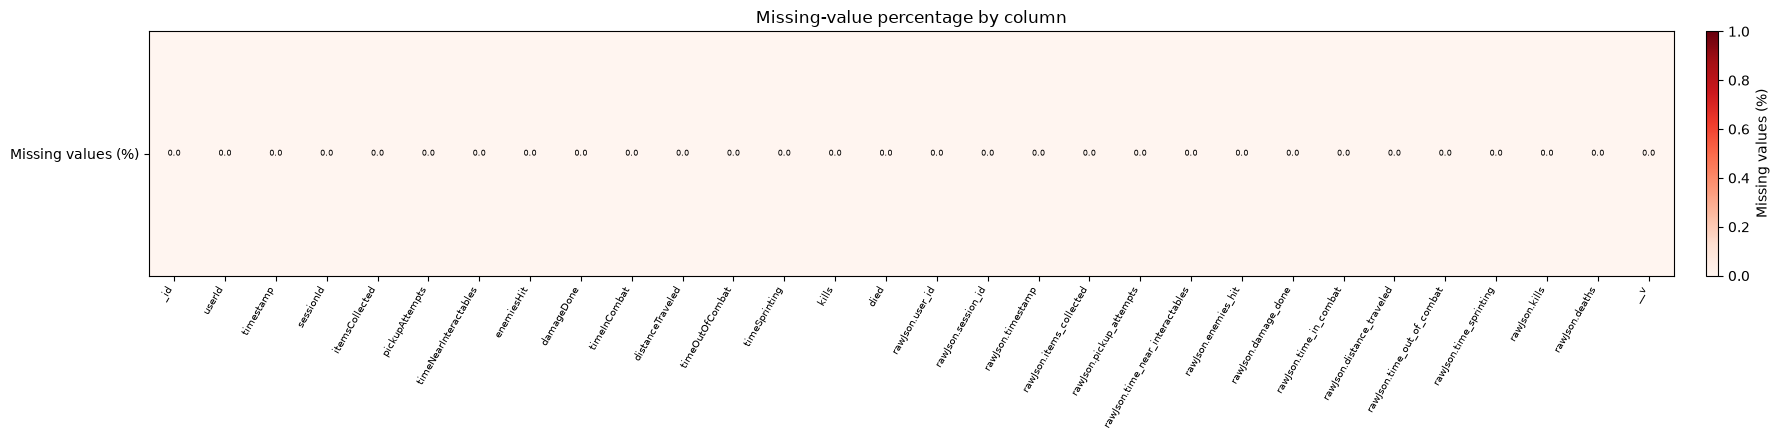

Fully duplicated rows: 0
No duplicate rows to display.
Column pairs with identical values: 13


,column_1,column_2
0,timestamp,rawJson.timestamp
1,sessionId,rawJson.session_id
2,itemsCollected,rawJson.items_collected
3,pickupAttempts,rawJson.pickup_attempts
4,timeNearInteractables,rawJson.time_near_interactables
5,enemiesHit,rawJson.enemies_hit
6,damageDone,rawJson.damage_done
7,timeInCombat,rawJson.time_in_combat
8,distanceTraveled,rawJson.distance_traveled
9,timeOutOfCombat,rawJson.time_out_of_combat


Potential outliers using the 1.5 x IQR rule:


,potential_outliers,outlier_percent,lower_fence,upper_fence,minimum,maximum
variable,,,,,,
itemsCollected,232,4.95,-3.000,5.000,0.0,13.000
pickupAttempts,481,10.25,-7.500,12.500,0.0,131.000
timeNearInteractables,383,8.16,-6.000,10.000,0.0,45.000
enemiesHit,243,5.18,-7.500,12.500,0.0,113.000
damageDone,134,2.86,-140.000,233.333,0.0,1568.000
timeInCombat,53,1.13,-14.250,23.750,0.0,30.500
distanceTraveled,5,0.11,-5330.284,20508.791,0.0,129162.675
timeOutOfCombat,39,0.83,2.500,46.500,0.0,194.500
timeSprinting,167,3.56,-16.500,27.500,0.0,201.500


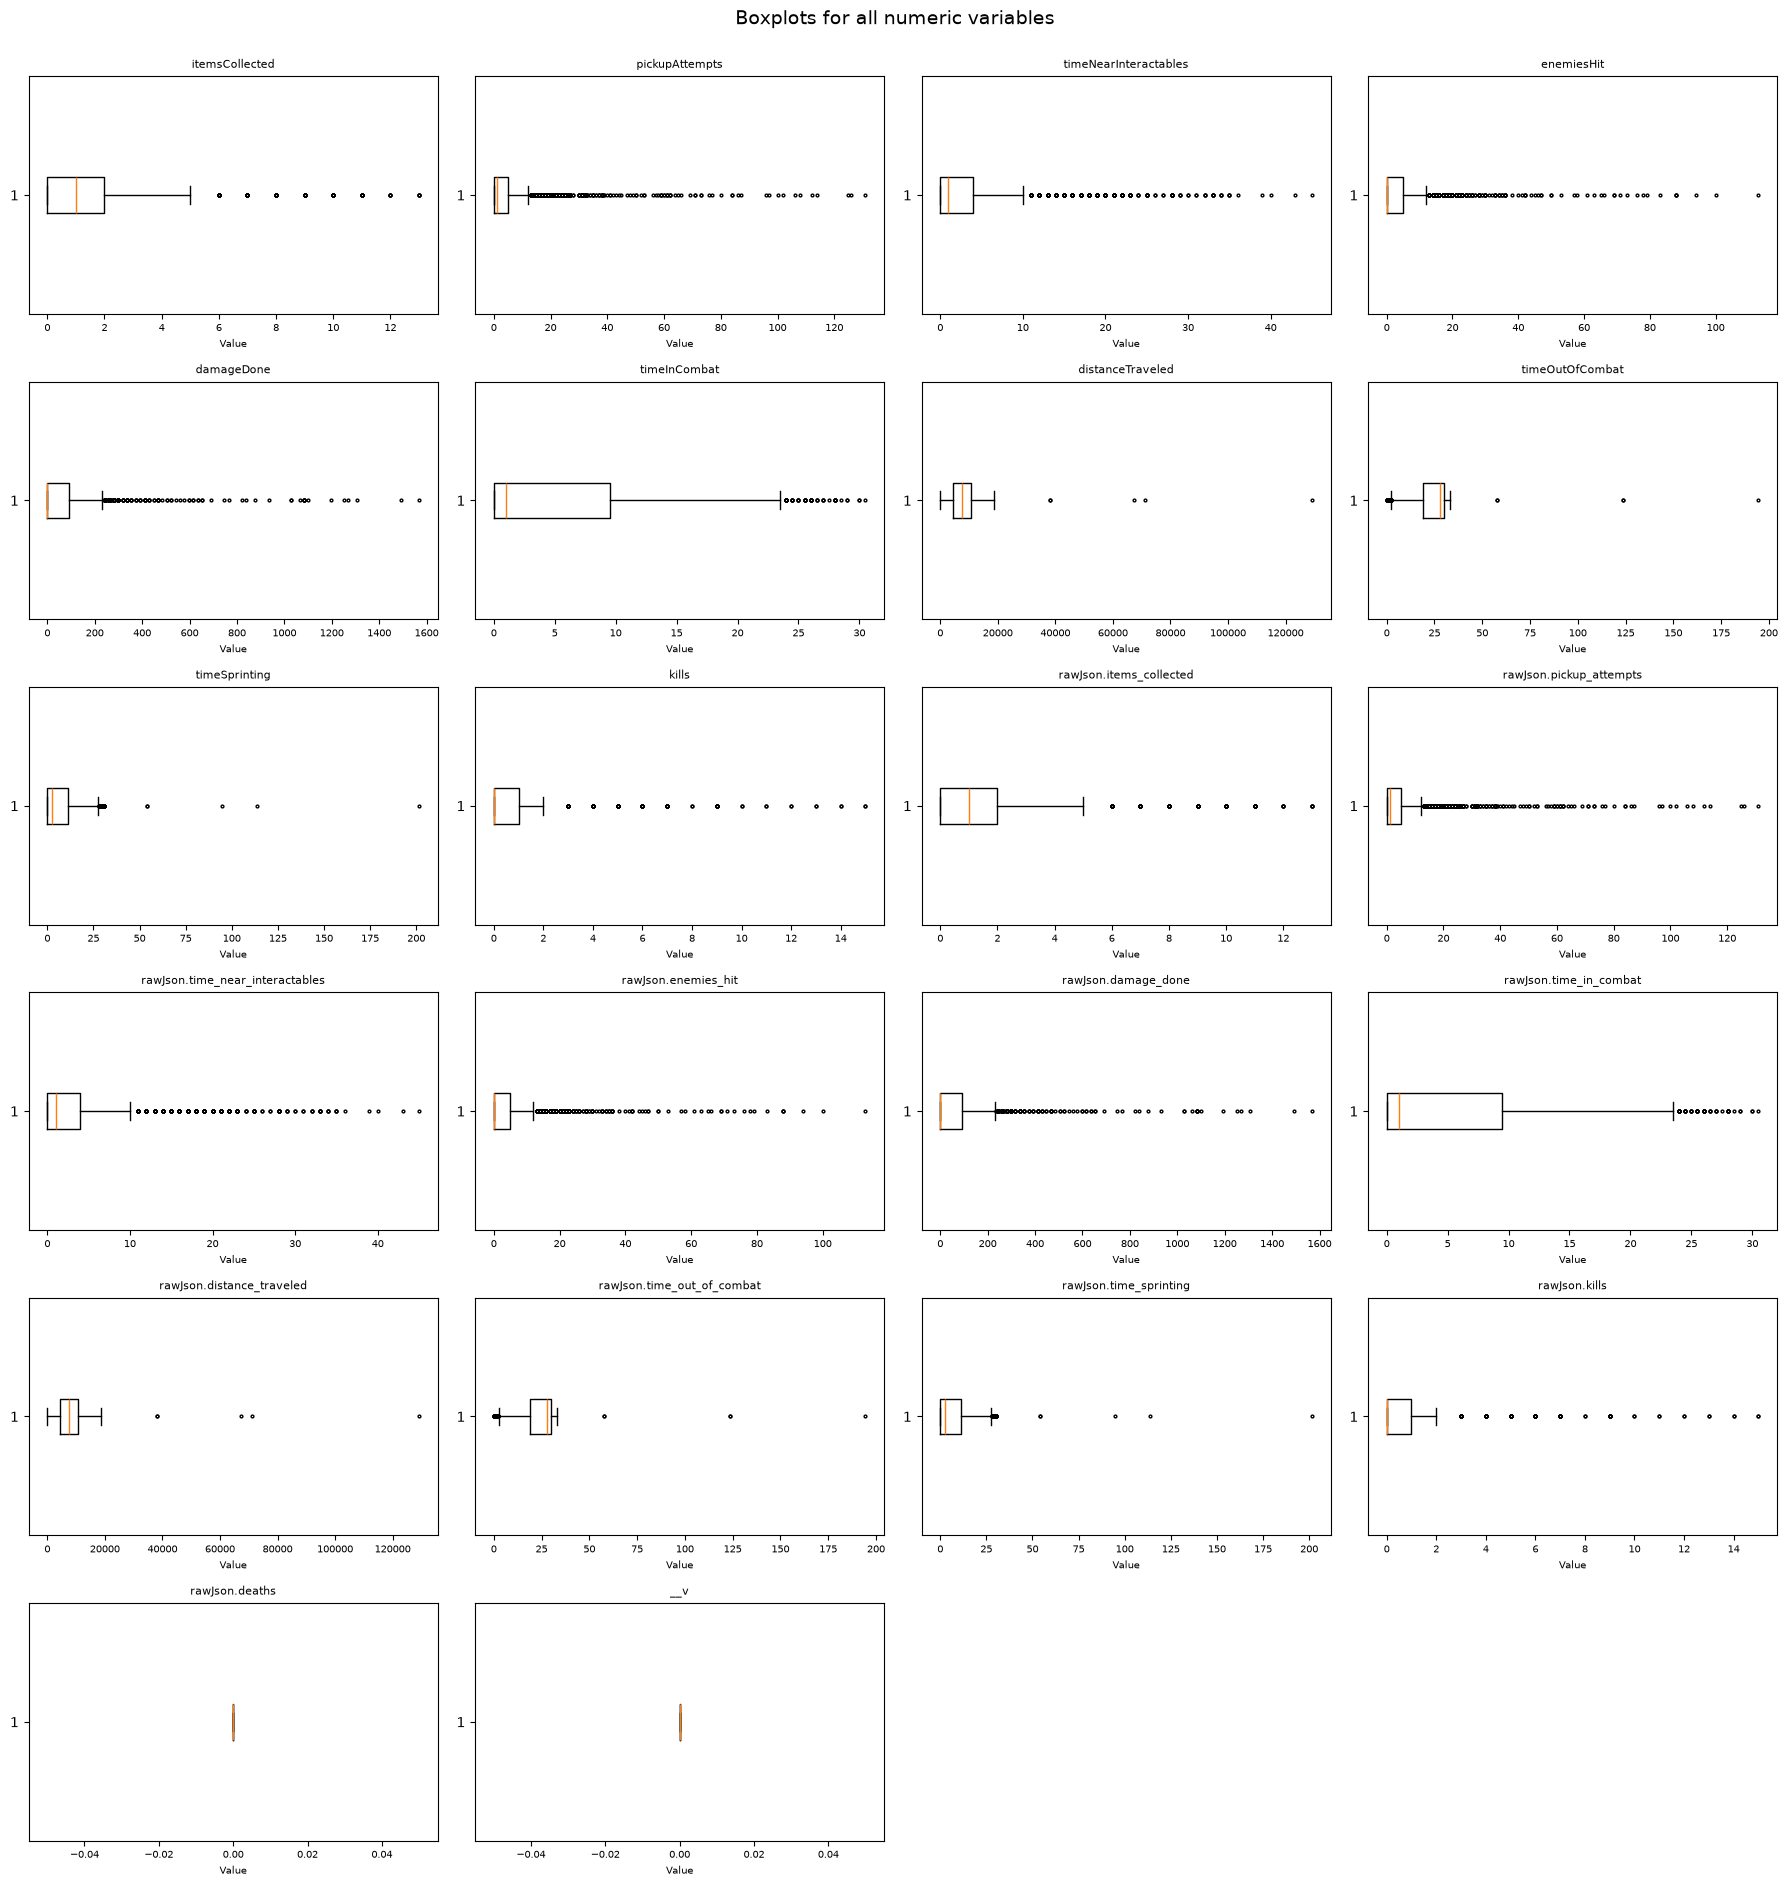

In [2]:
import math

import matplotlib.pyplot as plt

# Reuse the original DataFrame loaded in Task 1.
numeric_df = df.select_dtypes(include="number")

# Summarise missing values by column.
missing_summary = pd.DataFrame(
    {
        "missing_values": df.isna().sum(),
        "missing_percent": df.isna().mean().mul(100),
    }
).round({"missing_percent": 2})
print("Missing values by column:")
display(missing_summary)
print(f"Total missing values: {int(df.isna().sum().sum()):,}")

# Plot a heatmap of the missing-value percentage for each column.
missing_percent = df.isna().mean().mul(100)
fig, ax = plt.subplots(figsize=(18, 4.5))
heatmap = ax.imshow(
    missing_percent.to_numpy()[None, :],
    aspect="auto",
    cmap="Reds",
    vmin=0,
    vmax=max(1.0, float(missing_percent.max())),
)
ax.set_yticks([0], ["Missing values (%)"])
ax.set_xticks(range(len(df.columns)), df.columns, rotation=60, ha="right", fontsize=7)
for column_index, value in enumerate(missing_percent):
    ax.text(column_index, 0, f"{value:.1f}", ha="center", va="center", fontsize=6)
ax.set_title("Missing-value percentage by column")
fig.colorbar(heatmap, ax=ax, label="Missing values (%)", fraction=0.025, pad=0.02)
fig.tight_layout()
plt.show()

# Count fully duplicated rows and show examples if any.
duplicate_mask = df.duplicated()
duplicate_count = int(duplicate_mask.sum())
print(f"Fully duplicated rows: {duplicate_count:,}")
if duplicate_count:
    print("Examples of duplicate rows:")
    display(df.loc[duplicate_mask].head())
else:
    print("No duplicate rows to display.")

# Find pairs of columns with identical observed values.
duplicate_column_pairs = []
for left_index, left_column in enumerate(df.columns):
    for right_column in df.columns[left_index + 1 :]:
        if df[left_column].equals(df[right_column]):
            duplicate_column_pairs.append((left_column, right_column))
print(f"Column pairs with identical values: {len(duplicate_column_pairs)}")
if duplicate_column_pairs:
    display(pd.DataFrame(duplicate_column_pairs, columns=["column_1", "column_2"]))

# Use IQR fences to flag potential outliers; this does not imply that they are errors.
outlier_rows = []
for column in numeric_df.columns:
    q1 = numeric_df[column].quantile(0.25)
    q3 = numeric_df[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outlier_mask = (numeric_df[column] < lower_fence) | (numeric_df[column] > upper_fence)
    outlier_rows.append(
        {
            "variable": column,
            "potential_outliers": int(outlier_mask.sum()),
            "outlier_percent": round(float(outlier_mask.mean() * 100), 2),
            "lower_fence": round(float(lower_fence), 3),
            "upper_fence": round(float(upper_fence), 3),
            "minimum": round(float(numeric_df[column].min()), 3),
            "maximum": round(float(numeric_df[column].max()), 3),
        }
    )
outlier_summary = pd.DataFrame(outlier_rows).set_index("variable")
print("Potential outliers using the 1.5 x IQR rule:")
display(outlier_summary)

# Draw a boxplot for every numeric column, including duplicates and constants.
columns_per_row = 4
row_count = math.ceil(len(numeric_df.columns) / columns_per_row)
fig, axes = plt.subplots(
    nrows=row_count,
    ncols=columns_per_row,
    figsize=(18, 3.2 * row_count),
    squeeze=False,
)
for index, column in enumerate(numeric_df.columns):
    ax = axes.flat[index]
    ax.boxplot(
        numeric_df[column].dropna(),
        orientation="horizontal",
        flierprops={"markersize": 2},
    )
    ax.set_title(column, fontsize=8)
    ax.set_xlabel("Value", fontsize=7)
    ax.tick_params(axis="x", labelsize=7)
for ax in axes.flat[len(numeric_df.columns) :]:
    ax.set_visible(False)
fig.suptitle("Boxplots for all numeric variables", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

## Task 2: Data Quality Assessment

### Initial observations

- Missing values: No missing values were found in the 4,691 records. The table and heatmap show 0 missing values (0.0%) in every column.
- Duplicate rows: No fully duplicated rows were found. There are 13 pairs of columns with identical observed values. Most are flattened telemetry fields duplicated under `rawJson.*`; `rawJson.deaths` and `__v` are constant at 0. This is column-level redundancy, not duplicated records. The source schema should be checked before removing columns during later preprocessing.
- Constant columns: `died` is `False` in every row; `rawJson.deaths` and `__v` are always 0. These fields have no variation in this dataset and are unlikely to be useful predictors unless their source meaning is clarified.
- Potential outliers: The 1.5 × IQR rule flags high values in several behavioural variables. For example, `pickupAttempts` has 481 records (10.25%) flagged, `timeNearInteractables` has 383 (8.16%), and `enemiesHit` has 243 (5.18%). Five `distanceTraveled` records (0.11%) are flagged; the maximum is 129,162.675, above the upper fence of 20,508.791. The corresponding `rawJson.*` copies have the same flagged counts.
- Interpretation: The IQR rule identifies values for investigation; it does not establish that they are errors. High activity values may represent valid gameplay.
- Boxplots: Boxplots were produced for all 22 numeric columns in the raw table. Some plots repeat because `rawJson.*` columns duplicate other values; the two constant numeric columns appear as single lines. `died` is Boolean and is not included among the numeric columns.

## Task 3: Target Variable Preparation

### Target selection and class boundaries

The numerical target is `distanceTraveled` (`float64`), used as a proxy for movement in an individual telemetry record. The dataset provides neither a unit nor validated game-design thresholds, so `pandas.qcut` was used to divide the values into three relative, equal-frequency classes. This produces similar class sizes but does not make the cut-offs universal game-design standards.

Approximate boundaries derived from this dataset are:

- Low exploration: 0 to 5,578.393
- Medium exploration: above 5,578.393 to 9,561.131
- High exploration: above 9,561.131

These thresholds depend on the current dataset and may change if the data change. They describe relative movement, not an established difficulty standard. After discretisation, the task becomes a three-class classification problem; the original `distanceTraveled` variable remains numerical. Since `rawJson.distance_traveled` has identical observed values, both columns must be excluded from predictors in any later model to prevent target leakage.

The target has a long right tail (maximum 129,162.675), so the High exploration class spans a wider range. The class distribution and summary statistics for the original target are generated in the next cell.

Original target: distanceTraveled
Original target data type: float64
Problem type after discretisation: multiclass classification (3 classes)
Binning method: equal-frequency binning using pandas.qcut
Class boundaries: [0.0, 5578.393, 9561.131, 129162.675]
Summary statistics for the original numerical target:


,distanceTraveled
count,4691.000000
mean,7653.058030
std,4982.384836
min,0.000000
25%,4359.369166
50%,7659.476777
75%,10819.137902
max,129162.674662


Target class distribution:


,count,percent
exploration_class,,
Low exploration,1564,33.34
Medium exploration,1563,33.32
High exploration,1564,33.34


Original target statistics by class:


,count,minimum,median,maximum
exploration_class,,,,
Low exploration,1564,0.000,2891.169,5578.074
Medium exploration,1563,5579.031,7659.477,9560.992
High exploration,1564,9561.200,12158.696,129162.675


No severe class imbalance: the largest class accounts for 33.34%.


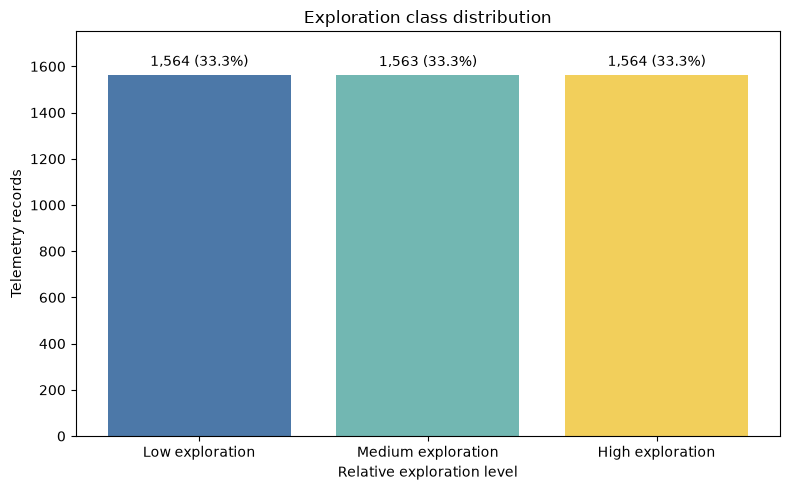

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Keep the source DataFrame unchanged and create the derived target in a copy.
target_name = "distanceTraveled"
target_class_name = "exploration_class"
class_labels = ["Low exploration", "Medium exploration", "High exploration"]
df_task3 = df.copy()

df_task3[target_class_name], bin_edges = pd.qcut(
    df_task3[target_name],
    q=3,
    labels=class_labels,
    retbins=True,
    duplicates="raise",
)

print(f"Original target: {target_name}")
print(f"Original target data type: {df[target_name].dtype}")
print(f"Problem type after discretisation: multiclass classification ({len(class_labels)} classes)")
print("Binning method: equal-frequency binning using pandas.qcut")
print("Class boundaries:", [round(float(edge), 3) for edge in bin_edges])

print("Summary statistics for the original numerical target:")
display(df[target_name].describe().to_frame("distanceTraveled"))

class_counts = df_task3[target_class_name].value_counts(sort=False)
class_distribution = pd.DataFrame(
    {
        "count": class_counts,
        "percent": class_counts.div(len(df_task3)).mul(100),
    }
).round({"percent": 2})
print("Target class distribution:")
display(class_distribution)

print("Original target statistics by class:")
class_summary = (
    df_task3.groupby(target_class_name, observed=False)[target_name]
    .agg(count="count", minimum="min", median="median", maximum="max")
    .round(3)
)
display(class_summary)

largest_class_share = float(class_distribution["percent"].max())
if largest_class_share > 80:
    print("Warning: one target class accounts for more than 80% of observations.")
else:
    print(f"No severe class imbalance: the largest class accounts for {largest_class_share:.2f}%.")

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(class_counts.index.astype(str), class_counts.values, color=["#4C78A8", "#72B7B2", "#F2CF5B"])
for bar, count in zip(bars, class_counts.values):
    ax.annotate(
        f"{count:,} ({count / len(df_task3):.1%})",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points",
    )
ax.set_title("Exploration class distribution")
ax.set_xlabel("Relative exploration level")
ax.set_ylabel("Telemetry records")
ax.set_ylim(0, max(class_counts.values) * 1.12)
fig.tight_layout()
plt.show()

## Task 4: Univariate Analysis

### Predictor scope

The target is `exploration_class`, derived from `distanceTraveled`. The behavioural predictors analysed are `itemsCollected`, `pickupAttempts`, `timeNearInteractables`, `enemiesHit`, `damageDone`, `timeInCombat`, `timeOutOfCombat`, `timeSprinting`, `kills`, and `died`. Identifiers (`_id`, `userId`, and `sessionId`) are not treated as measurements; `timestamp` is retained as metadata rather than used as a raw predictor. The `rawJson.*` duplicates and the original target column are excluded to avoid repeated statistics and target leakage.

### Distribution observations

- `itemsCollected`: median 1, 48.7% zeros, and right skew (skewness 2.10). Most records contain 0–2 collected items; the maximum is 13.
- `pickupAttempts`: median 1, with 40.6% zeros. The distribution is strongly right-skewed (5.77), has a long tail, and reaches 131.
- `timeNearInteractables`: median 1, with 41.8% zeros and right skew (2.78); most values are small and the maximum is 45.
- `enemiesHit`: median 0, with 53.9% zeros and strong right skew (6.09). A small number of records have many hits, up to 113.
- `damageDone`: median 0 and 54.0% zeros. The distribution is strongly right-skewed (6.04), with a maximum of 1,568; the mean is much higher than a typical value.
- `timeInCombat`: median 1, with 48.8% zeros and moderate right skew (1.16); most values are low and the maximum is 30.5.
- `timeOutOfCombat`: median 28 and 75th percentile 30, but the maximum is 194.5 and the distribution is right-skewed (1.84). The measurement window and field definition should be verified before interpreting the upper tail.
- `timeSprinting`: median 2.5, with 44.5% zeros and right skew (3.87); the maximum is 201.5.
- `kills`: median 0; 67.5% of records have zero kills. The distribution is strongly right-skewed (5.65), with a maximum of 15.
- `died`: Boolean; all 4,691 records are `False`. This variable has no variation and is not useful as a predictor in this dataset.

Overall, most behavioural variables contain many zeros and are right-skewed rather than normally distributed. Medians, quantiles, zero rates, and histograms are therefore more informative than the mean alone. High values flagged in Task 2 are retained because they may represent valid gameplay and should be checked against the field definitions. There are multiple telemetry records per player.

Predictors included in the univariate analysis:


,predictor,data_type
0,itemsCollected,int64
1,pickupAttempts,int64
2,timeNearInteractables,int64
3,enemiesHit,int64
4,damageDone,float64
5,timeInCombat,float64
6,timeOutOfCombat,float64
7,timeSprinting,float64
8,kills,int64
9,died,bool


Number of numeric predictors: 9
Number of Boolean/categorical predictors: 1
Descriptive statistics for all predictors:


,data_type,count,unique_values,most_common_value,frequency,mean,standard_deviation,minimum,25th_percentile,median,75th_percentile,maximum,skewness,zero_percent
itemsCollected,int64,4691.0,NaN,NaN,NaN,1.360264,1.973878,0.0,0.0,1.0,2.0,13.0,2.100,48.7
pickupAttempts,int64,4691.0,NaN,NaN,NaN,4.66489,9.671879,0.0,0.0,1.0,5.0,131.0,5.769,40.6
timeNearInteractables,int64,4691.0,NaN,NaN,NaN,3.198039,5.17994,0.0,0.0,1.0,4.0,45.0,2.783,41.8
enemiesHit,int64,4691.0,NaN,NaN,NaN,3.486677,7.336068,0.0,0.0,0.0,5.0,113.0,6.089,53.9
damageDone,float64,4691.0,NaN,NaN,NaN,52.310559,103.112381,0.0,0.0,0.0,93.333333,1568.0,6.041,54.0
timeInCombat,float64,4691.0,NaN,NaN,NaN,5.073758,6.549744,0.0,0.0,1.0,9.5,30.5,1.163,48.8
timeOutOfCombat,float64,4691.0,NaN,NaN,NaN,24.116606,8.209461,0.0,19.0,28.0,30.0,194.5,1.835,0.2
timeSprinting,float64,4691.0,NaN,NaN,NaN,6.370603,8.868964,0.0,0.0,2.5,11.0,201.5,3.870,44.5
kills,int64,4691.0,NaN,NaN,NaN,0.498614,1.108673,0.0,0.0,0.0,1.0,15.0,5.650,67.5
died,bool,4691,1,False,4691,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


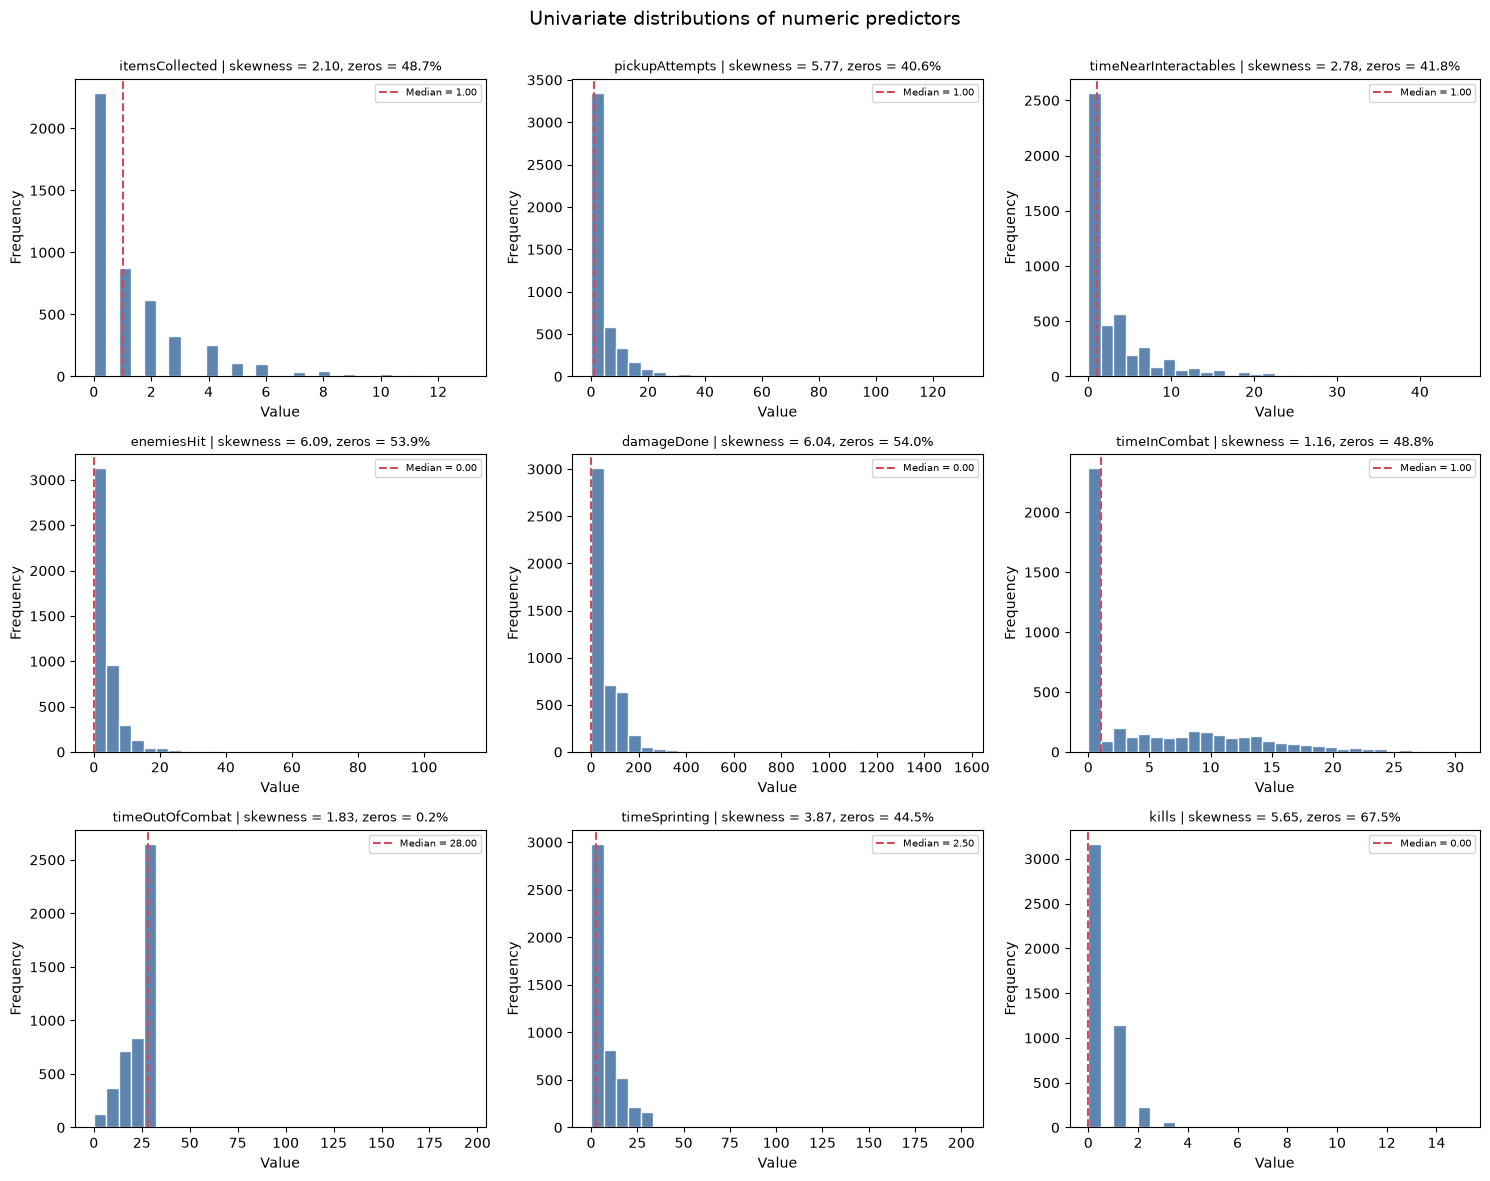

Distribution of died:


,count,percent
died,,
False,4691,100.0


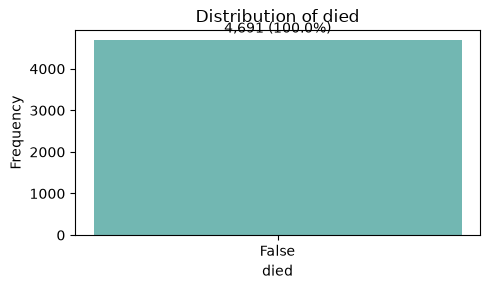

In [4]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

predictor_columns = [
    "itemsCollected",
    "pickupAttempts",
    "timeNearInteractables",
    "enemiesHit",
    "damageDone",
    "timeInCombat",
    "timeOutOfCombat",
    "timeSprinting",
    "kills",
    "died",
]
predictor_data = df_task3[predictor_columns]
numeric_predictors = predictor_data.select_dtypes(include="number").columns.tolist()
categorical_predictors = [column for column in predictor_columns if column not in numeric_predictors]

print("Predictors included in the univariate analysis:")
display(
    pd.DataFrame(
        {
            "predictor": predictor_columns,
            "data_type": predictor_data.dtypes.astype(str).reindex(predictor_columns).to_list(),
        }
    )
)
print(f"Number of numeric predictors: {len(numeric_predictors)}")
print(f"Number of Boolean/categorical predictors: {len(categorical_predictors)}")

# Calculate descriptive statistics for all selected predictors.
predictor_summary = predictor_data.describe(include="all").T
predictor_summary.insert(0, "data_type", predictor_data.dtypes.astype(str))
predictor_summary["skewness"] = np.nan
predictor_summary["zero_percent"] = np.nan
for column in numeric_predictors:
    predictor_summary.loc[column, "skewness"] = predictor_data[column].skew()
    predictor_summary.loc[column, "zero_percent"] = predictor_data[column].eq(0).mean() * 100
predictor_summary = predictor_summary.rename(
    columns={
        "count": "count",
        "unique": "unique_values",
        "top": "most_common_value",
        "freq": "frequency",
        "mean": "mean",
        "std": "standard_deviation",
        "min": "minimum",
        "25%": "25th_percentile",
        "50%": "median",
        "75%": "75th_percentile",
        "max": "maximum",
    }
)
predictor_summary["skewness"] = predictor_summary["skewness"].round(3)
predictor_summary["zero_percent"] = predictor_summary["zero_percent"].round(1)
print("Descriptive statistics for all predictors:")
display(predictor_summary)

# Plot a histogram for each numeric predictor.
columns_per_row = 3
row_count = math.ceil(len(numeric_predictors) / columns_per_row)
fig, axes = plt.subplots(
    nrows=row_count,
    ncols=columns_per_row,
    figsize=(15, 4 * row_count),
    squeeze=False,
)
for index, column in enumerate(numeric_predictors):
    ax = axes.flat[index]
    values = predictor_data[column].dropna()
    ax.hist(values, bins=30, color="#4C78A8", edgecolor="white", alpha=0.9)
    median = values.median()
    ax.axvline(median, color="#D1495B", linestyle="--", linewidth=1.5, label=f"Median = {median:.2f}")
    zero_percent = values.eq(0).mean() * 100
    ax.set_title(f"{column} | skewness = {predictor_data[column].skew():.2f}, zeros = {zero_percent:.1f}%", fontsize=9)
    ax.set_xlabel("Value")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=7)
for ax in axes.flat[len(numeric_predictors) :]:
    ax.set_visible(False)
fig.suptitle("Univariate distributions of numeric predictors", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

# Summarise and plot categorical/Boolean predictors.
for column in categorical_predictors:
    counts = predictor_data[column].value_counts(dropna=False)
    distribution = pd.DataFrame(
        {
            "count": counts,
            "percent": counts.div(len(predictor_data)).mul(100).round(2),
        }
    )
    print(f"Distribution of {column}:")
    display(distribution)
    fig, ax = plt.subplots(figsize=(5, 3))
    bars = ax.bar(counts.index.astype(str), counts.values, color="#72B7B2")
    for bar, count in zip(bars, counts.values):
        ax.annotate(
            f"{count:,} ({count / len(predictor_data):.1%})",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            ha="center",
            va="bottom",
            xytext=(0, 3),
            textcoords="offset points",
        )
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    fig.tight_layout()
    plt.show()

## Task 5: Multivariate Analysis

### Method and initial observations

The correlation heatmap uses Spearman rank correlation for the nine numeric predictors and the ordinal target code (`Low exploration` = 0, `Medium exploration` = 1, `High exploration` = 2). This is suitable for an ordinal target and skewed gameplay variables. Pearson coefficients are also reported for the three strongest associations and used to screen for strong linear relationships between predictors.

The three largest absolute Spearman associations with `exploration_class` are:

1. `timeSprinting`: 0.621 (Pearson: 0.577)
2. `itemsCollected`: 0.564 (Pearson: 0.511)
3. `pickupAttempts`: 0.521 (Pearson: 0.352)

These are positive associations: records in the higher exploration class tend to have more sprinting, items collected, and pickup attempts. This does not show that these behaviours cause greater exploration.

Using |r| ≥ 0.70 as a Pearson screening threshold, four predictor pairs show strong linear association: `enemiesHit`–`damageDone` (0.972), `enemiesHit`–`kills` (0.862), `damageDone`–`kills` (0.840), and `timeInCombat`–`timeOutOfCombat` (-0.765). These pairs may contain overlapping information; their definitions should be checked and redundancy considered during later modelling. Correlation does not demonstrate causality and does not automatically mean a variable should be removed.

The pairplot focuses on the three predictors most strongly associated with the target, with points coloured by exploration class to examine monotonic trends and class overlap.

Target correlations: Spearman is prioritised because the target is ordinal and predictors are skewed.


,Spearman rho,Pearson r
timeSprinting,0.621,0.577
itemsCollected,0.564,0.511
pickupAttempts,0.521,0.352


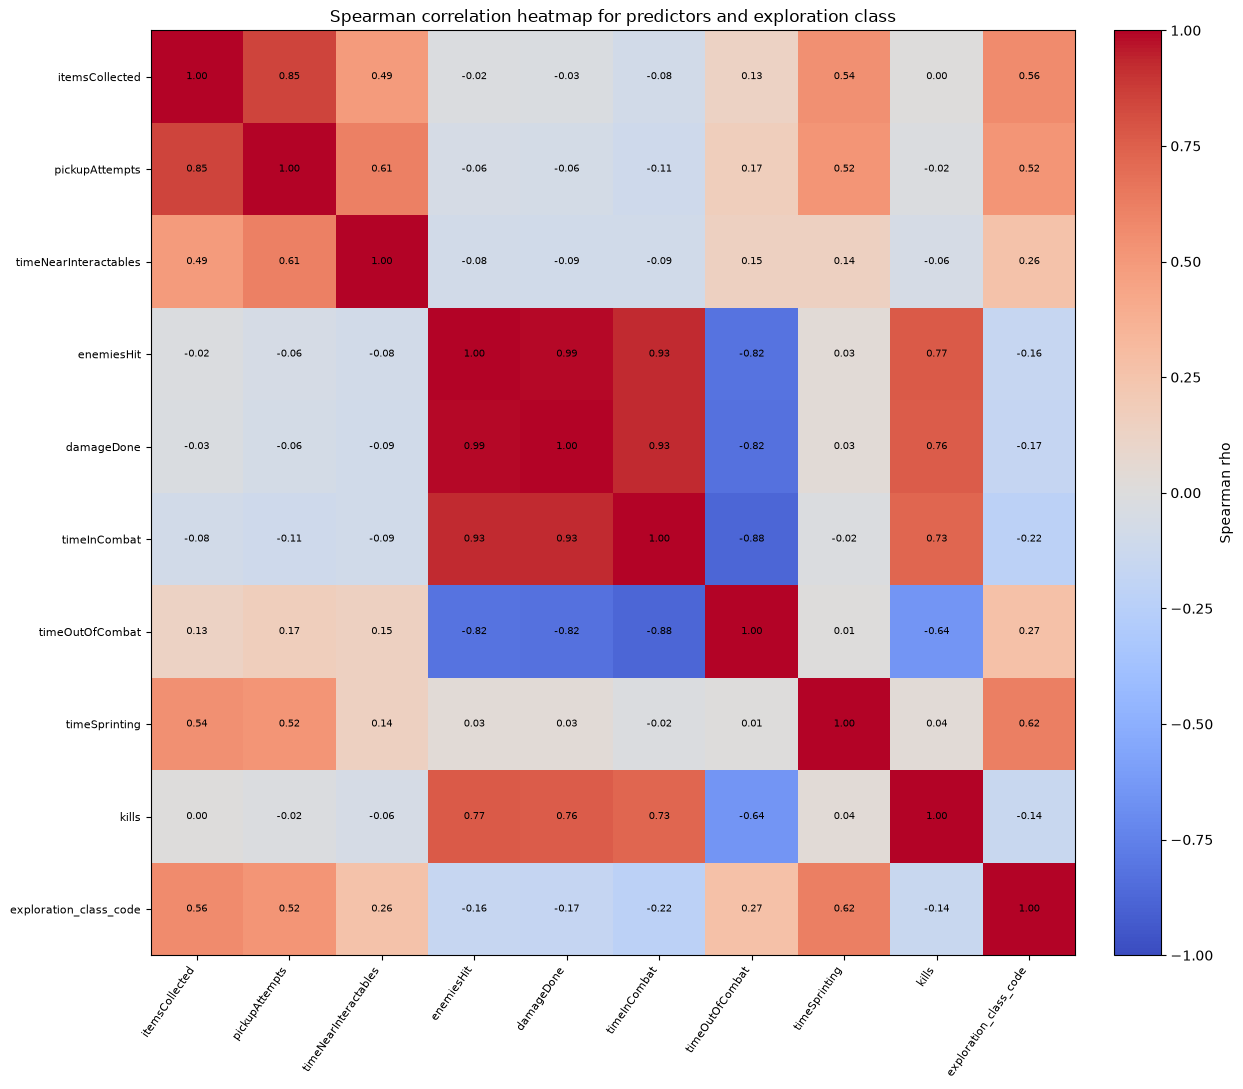

Predictor pairs with |Pearson r| >= 0.70:


,variable_1,variable_2,Pearson r
0,enemiesHit,damageDone,0.972
1,enemiesHit,kills,0.862
2,damageDone,kills,0.840
3,timeInCombat,timeOutOfCombat,-0.765


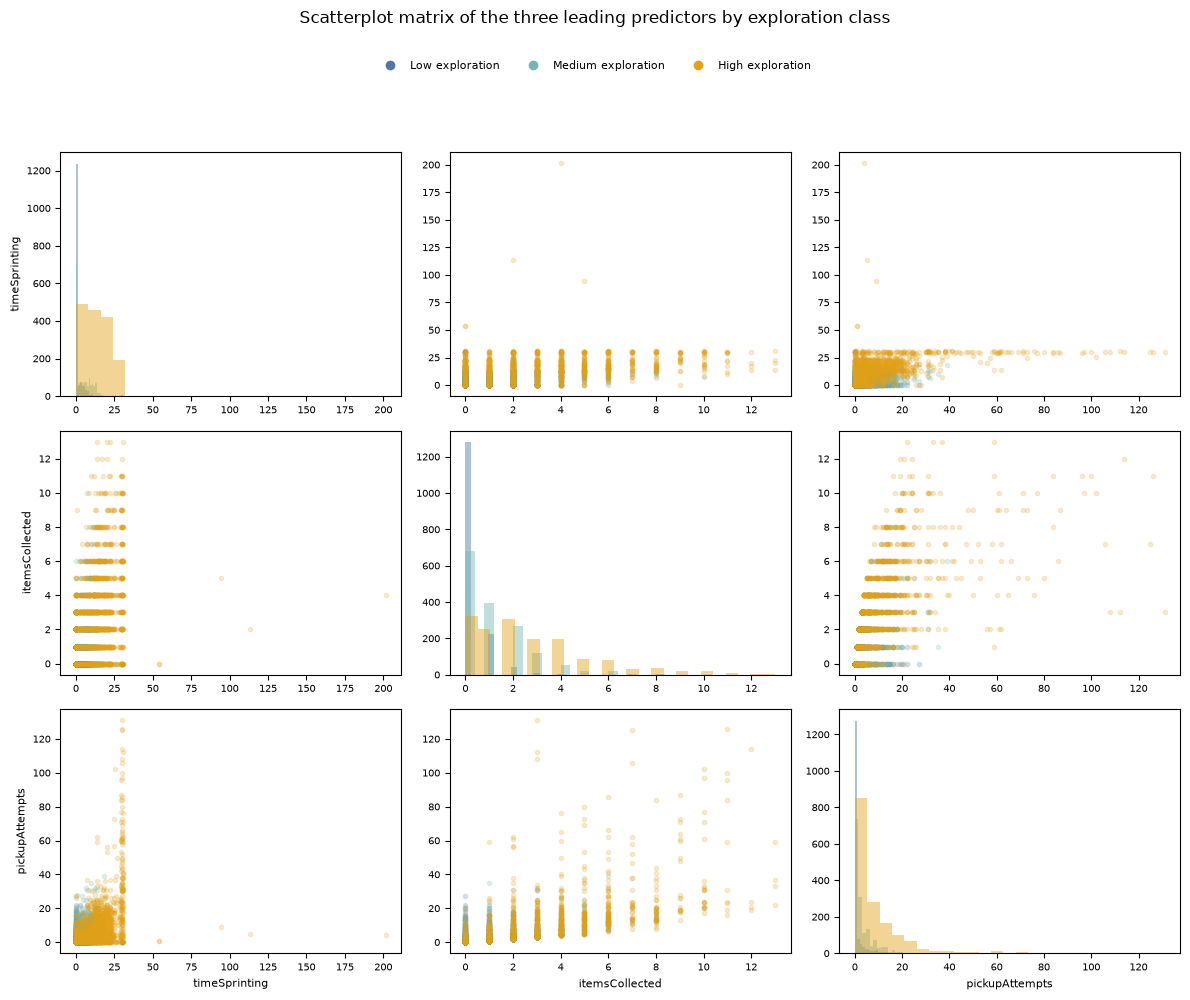

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

# Encode the ordinal target as 0, 1, and 2 for correlation analysis.
ordinal_target_name = "exploration_class_code"
correlation_data = df_task3[numeric_predictors].copy()
correlation_data[ordinal_target_name] = df_task3[target_class_name].cat.codes
spearman_correlation = correlation_data.corr(method="spearman")
pearson_correlation = correlation_data.corr(method="pearson")

print("Target correlations: Spearman is prioritised because the target is ordinal and predictors are skewed.")
target_spearman = spearman_correlation[ordinal_target_name].drop(ordinal_target_name)
target_pearson = pearson_correlation[ordinal_target_name].drop(ordinal_target_name)
top_features = target_spearman.abs().sort_values(ascending=False).head(3).index.tolist()
top_correlation_table = pd.DataFrame(
    {
        "Spearman rho": target_spearman.loc[top_features],
        "Pearson r": target_pearson.loc[top_features],
    }
).round(3)
display(top_correlation_table)

# Plot a Spearman heatmap for numeric predictors and the ordinal target code.
fig, ax = plt.subplots(figsize=(14, 11))
heatmap = ax.imshow(spearman_correlation, cmap="coolwarm", vmin=-1, vmax=1)
correlation_labels = spearman_correlation.columns.tolist()
ax.set_xticks(range(len(correlation_labels)), correlation_labels, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(len(correlation_labels)), correlation_labels, fontsize=8)
for row_index in range(len(correlation_labels)):
    for column_index in range(len(correlation_labels)):
        ax.text(
            column_index,
            row_index,
            f"{spearman_correlation.iloc[row_index, column_index]:.2f}",
            ha="center",
            va="center",
            fontsize=7,
        )
ax.set_title("Spearman correlation heatmap for predictors and exploration class")
fig.colorbar(heatmap, ax=ax, label="Spearman rho", fraction=0.04, pad=0.03)
fig.tight_layout()
plt.show()

# Use Pearson correlation to screen for strongly linearly associated predictor pairs.
correlation_threshold = 0.70
pearson_predictor_correlation = df_task3[numeric_predictors].corr(method="pearson")
high_correlation_pairs = []
for left_index, left_feature in enumerate(numeric_predictors):
    for right_feature in numeric_predictors[left_index + 1 :]:
        coefficient = pearson_predictor_correlation.loc[left_feature, right_feature]
        if abs(coefficient) >= correlation_threshold:
            high_correlation_pairs.append(
                {
                    "variable_1": left_feature,
                    "variable_2": right_feature,
                    "Pearson r": coefficient,
                    "absolute_r": abs(coefficient),
                }
            )
high_correlation_table = pd.DataFrame(high_correlation_pairs)
if not high_correlation_table.empty:
    high_correlation_table = high_correlation_table.sort_values("absolute_r", ascending=False).drop(columns="absolute_r")
print(f"Predictor pairs with |Pearson r| >= {correlation_threshold:.2f}:")
if high_correlation_table.empty:
    print("No highly correlated predictor pairs were found at this threshold.")
else:
    display(high_correlation_table.round(3).reset_index(drop=True))

# Create a scatterplot matrix for the three predictors most associated with the target, coloured by class.
pairplot_data = df_task3[top_features + [target_class_name]].copy()
class_order = df_task3[target_class_name].cat.categories.tolist()
class_colors = {
    "Low exploration": "#4C78A8",
    "Medium exploration": "#72B7B2",
    "High exploration": "#E3A018",
}
fig, axes = plt.subplots(3, 3, figsize=(12, 10), squeeze=False)
for row_index, y_feature in enumerate(top_features):
    for column_index, x_feature in enumerate(top_features):
        ax = axes[row_index, column_index]
        if row_index == column_index:
            for class_label in class_order:
                values = pairplot_data.loc[
                    pairplot_data[target_class_name] == class_label,
                    x_feature,
                ]
                ax.hist(
                    values,
                    bins=25,
                    alpha=0.45,
                    color=class_colors[class_label],
                )
        else:
            for class_label in class_order:
                class_rows = pairplot_data[target_class_name] == class_label
                ax.scatter(
                    pairplot_data.loc[class_rows, x_feature],
                    pairplot_data.loc[class_rows, y_feature],
                    s=9,
                    alpha=0.2,
                    color=class_colors[class_label],
                )
        if row_index == 2:
            ax.set_xlabel(x_feature, fontsize=8)
        if column_index == 0:
            ax.set_ylabel(y_feature, fontsize=8)
        ax.tick_params(labelsize=7)
legend_handles = [
    Line2D([], [], color=class_colors[label], marker="o", linestyle="", label=label)
    for label in class_order
]
fig.suptitle("Scatterplot matrix of the three leading predictors by exploration class", y=0.995, fontsize=12)
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=3, frameon=False, fontsize=8)
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

## Task 6: Engineering Interpretation

### 1. What do the correlations mean for game design?

- `timeSprinting` has the strongest positive Spearman association with relative exploration (rho = 0.621). This is mechanically plausible because sprinting contributes to movement. However, the target is derived from `distanceTraveled`, so this association is partly expected and does not prove that sprinting causes greater exploration.
- `itemsCollected` (rho = 0.564) and `pickupAttempts` (rho = 0.521) also increase with the exploration class. Players who travel farther may encounter or attempt to interact with more objects. `itemsCollected` and `pickupAttempts` are also strongly associated (Spearman rho = 0.848), potentially reflecting the item-collection loop.
- Combat variables are strongly associated: Pearson r is 0.972 for `enemiesHit` and `damageDone`, 0.862 for `enemiesHit` and `kills`, and 0.840 for `damageDone` and `kills`. This is consistent with related stages of combat, but the variables may contain overlapping information in a future model.
- `timeInCombat` and `timeOutOfCombat` have Pearson r = -0.765. They may describe opposing portions of the same telemetry window, but their definitions and calculations should be verified before interpreting this as a gameplay relationship.

### 2. Unexpected patterns

Combat metrics have weak negative Spearman associations with the distance-based exploration class: `timeInCombat` rho = -0.225, `damageDone` rho = -0.167, `enemiesHit` rho = -0.160, and `kills` rho = -0.143. This may reflect different movement-focused and combat-focused play styles. Alternatively, the metrics may use different time windows or be affected by player or session context. This pattern alone does not show a game-design problem.

The `died` field is `False` in all 4,691 telemetry records, and `rawJson.deaths` is always 0, although the downloaded dataset includes a separate death-events table. Death events may not be represented or joined at the telemetry-record level. The join key and time alignment should be checked before concluding that players did not die.

### 3. Gameplay processes represented in the data

The measurements suggest three interacting gameplay loops: movement/exploration (`distanceTraveled`, `timeSprinting`), collection and interaction (`pickupAttempts`, `itemsCollected`, `timeNearInteractables`), and combat (`enemiesHit`, `damageDone`, `kills`, `timeInCombat`). Correlation shows that some behaviours co-occur; it does not establish causality. The data do not control for level layout, objectives, enemy density, player skill, or session duration.

### 4. Additional features needed for stronger conclusions

- Level and spatial context: map/zone, level ID, position or route, objective locations, and distance to interactable objects or enemies.
- Difficulty and combat context: selected difficulty, enemy type/count/health, encounter start/end times, player health, weapon/loadout, upgrades, and checkpoints.
- Outcomes and progression: objective/level completion, wins/losses, retries, abandonment, session duration, and death-event labels aligned to the correct telemetry window.
- Measurement metadata: distance/time units, sampling interval, whether variables are cumulative or window-based, game version, and session boundaries.
- Player context: prior experience/skill and stable player/session identifiers for grouping. The table has 4,691 telemetry records but only 68 users, so rows should not be treated as independent players.

Without these features, conclusions about difficulty, balance, and the causal effects of design changes are limited.

## Task 7: Data Challenges

- The raw telemetry table has no missing values or fully duplicated rows, but it contains 13 pairs of columns with identical observed values (`rawJson.*` and constant fields). The schema must be checked to distinguish export duplicates from meaningful fields.
- The IQR rule flags high behavioural values, including `pickupAttempts`, `damageDone`, and `distanceTraveled`. Because the units and measurement windows have not been confirmed, these values may be errors or valid gameplay events; they are retained for now.
- `died` is always `False` in this table, while a separate death-events file is available. Joining those events to telemetry by timestamp has not yet been completed.
- The 4,691 telemetry records belong to 68 players. Treating the rows as 4,691 independent players would overstate the effective sample size.

## Task 8: Responsible AI Reflection

- Data quality and reliability: incorrect units, duplicate columns, outliers, or unsynchronised death labels may distort distributions and correlations. A model based on such data could produce unreliable conclusions about gameplay.
- Bias and ethics: the data come from one custom game and 68 players, so they may not represent other games, player groups, devices, or play styles. Although IDs are anonymised, records can still be linked over time; access and retention should be limited. Game-design decisions should consider accessibility and player well-being, not only maximise time played.

## Task 9: Summary and Modelling Insights


### Dataset overview
AURA raw gameplay telemetry from a custom 3D game, sourced from Kaggle under CC BY-SA 4.0. The selected table contains 4,691 telemetry records, 30 raw columns, and 68 users. Each row is a telemetry record, not a unique player.

### Data quality and target
There are no missing values or fully duplicated rows. Thirteen pairs of columns have identical observed values; `died` is always `False`, and two numeric columns are constant. The IQR rule flags potential outliers, which are retained pending confirmation of units and measurement windows. The numerical target `distanceTraveled` was divided by equal-frequency binning into Low, Medium, and High exploration classes (approximate cut-offs: 5,578.393 and 9,561.131), with 1,564, 1,563, and 1,564 records respectively.

### EDA findings and engineering interpretation
The nine numeric predictors are mostly zero-heavy and right-skewed. The strongest Spearman associations with the exploration class are `timeSprinting` (0.621), `itemsCollected` (0.564), and `pickupAttempts` (0.521). Pearson screening identifies strongly associated predictor pairs: `enemiesHit`–`damageDone` (0.972), `enemiesHit`–`kills` (0.862), `damageDone`–`kills` (0.840), and `timeInCombat`–`timeOutOfCombat` (-0.765). These patterns are consistent with movement, collection, and combat loops, but they do not establish causality.

### Initial insights for modelling
`timeSprinting`, `itemsCollected`, and `pickupAttempts` are promising exploratory predictors of the relative distance class. Before modelling, exclude `distanceTraveled` and its duplicate `rawJson.distance_traveled` to prevent target leakage; review duplicate/constant fields and confirm units and telemetry windows. Scaling may be useful for distance-based or linear models, while tree-based models are less sensitive to feature scale. Compare a simple ordinal or multinomial logistic-regression baseline with a tree-based classifier. Because records repeat within users and sessions, evaluate with group-aware splits by player/session rather than treating every record as independent. These are modelling suggestions only; no predictive model has been trained in this assessment.

### Limitations and next steps
Confirm telemetry units, sampling windows, and whether measurements are cumulative or window-based; align death events with the `died` field; obtain level, map, objective, difficulty, and encounter context; and account for repeated records from the same player/session in future analyses. This Portfolio Assessment 1 notebook performs EDA and preparation only; it does not train a predictive model.

### Generative AI declaration
Microsoft Copilot was used to translate and edit the language of this notebook from Vietnamese into English.